Simulate the model for  = 0.5 and I ∈ [0.9, 3], and plot the firing number (spikes per forcing period, measured after a transient) against I, along with the unforced firing number 1/ log[I/(I − 1)] for I > 1 (zero for I ≤ 1). Mark the tongue boundaries from part (a) and compare with the measured 1:1 plateau. Identify at least four other plateaus, and report the phase of the spikes at I = 1.6. Hint: between spikes v(t) = G(t) + [v(Tn) − G(Tn)]e−(t−Tn) exactly, so you only need to locate threshold crossings.

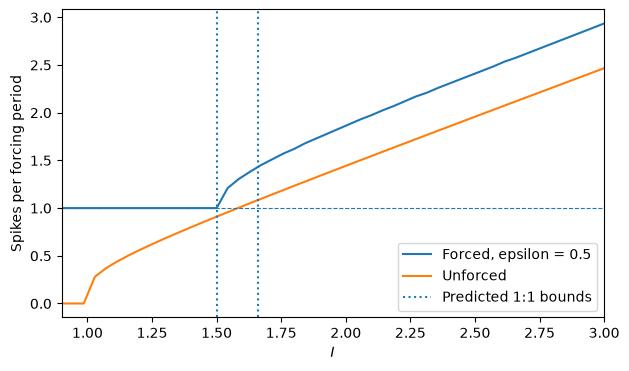


Approximate Plateau Regions:
2:3: I = 0.9000 to 1.5000
1:1: I = 0.9000 to 1.6286
3:2: I = 1.5429 to 2.0143
2:1: I = 1.8000 to 2.4857

At I = 1.6:
Firing number = 1.3300
Mean spike phase = 0.6278 cycles


In [10]:
import numpy as np 
import matplotlib.pyplot as plt  


def lif_sim(I = 1.1, T = 10.0, dt = 1e-3, taum = 1.0, R = 1.0, urest = 0.0, uth = 1.0, sigma = 0.0, seed = None):
    rng = np.random.default_rng(seed)
    Ifun = I if callable(I) else (lambda t: I)

    nt = int(round(T / dt)) + 1
    t = np.linspace(0.0, T, nt)
    u = np.zeros(nt)
    u[0] = urest
    spikes = []

    for j in range(nt - 1):
        du = dt * (R * Ifun(t[j] - (u[j] - urest)) / taum)
        if sigma:
            du += np.sqrt(2 * dt) * sigma * rng.standard_normal()
        u[j + 1] = u[j] + du
        if u[j + 1] > uth:
            u[j + 1] = urest
            spikes.append(t[j + 1])

    return t, u, np.array(spikes)

# Specific 1c Parameters
epsilon = 0.5
I_range = np.linspace(0.9, 3)
T_forcing = 1.0
transient = 400
measured = 200
firing_number = []

# Forced Simulation
for I in I_range: 
    T_tot = (transient + measured) * T_forcing
    Ifun = lambda t, I = I: I + epsilon * np.sin(2 * np.pi * t) 
    t ,u, spikes = lif_sim(
        I = Ifun, 
        T = T_tot,
        dt = 1e-3
    )

    # Ignore transient spiking
    spikes = spikes[spikes >= transient * T_forcing]

    # Include spikes in measured forcing period
    firing_number.append(len(spikes) / measured)

# Unforced simulation
firing_unforced = np.zeros_like(I_range)
mask = I_range > 1
firing_unforced[mask] = 1 / np.log(I_range[mask] / (I_range[mask] -1))

# Arnold Tounge Boundaries
I_star = 1.582
slope = np.sqrt(1 + (4 * np.pi**2))
I_left = I_star - epsilon / slope
I_right = I_star + epsilon / slope

# Plot
plt.figure(figsize = (7, 4))
plt.plot(I_range, firing_number, label='Forced, epsilon = 0.5')
plt.plot(I_range, firing_unforced, label='Unforced')
plt.axvline(I_left, linestyle = ":", label = "Predicted 1:1 bounds")
plt.axvline(I_right, linestyle = ":")

# 1:1 Plateau
plt.axhline(1, linestyle = "--", linewidth = 0.8)
plt.xlabel("$I$")
plt.ylabel("Spikes per forcing period")
plt.xlim(0.9, 3)
plt.legend()
plt.show()

# Identify the other plateau regions
firing_number = np.array(firing_number)
ratios = {
    "1:2": 1/2, 
    "2:3": 2/3, 
    "1:1": 1, 
    "3:2": 3/2, 
    "2:1": 2
}

print("\nApproximate Plateau Regions:")
for name, value, in ratios.items():
    close = np.abs(firing_number - value) < 0.4
    if np.any(close):
        I_plateau = I_range[close]
        print(f"{name}: I = {I_plateau.min():.4f} to {I_plateau.max():.4f}")

# For I = 1.6
I = 1.6
Ifun = lambda t: I + epsilon * np.sin(2 * np.pi * t)
t, u, spikes = lif_sim(
    I = Ifun,
    T = (transient + measured) * T_forcing,
    dt = 1e-3
)   
spikes = spikes[spikes >= transient * T_forcing]
phase = spikes % T_forcing

print("\nAt I = 1.6:")
print(f"Firing number = {len(spikes) / measured:.4f}")
print(f"Mean spike phase = {phase.mean():.4f} cycles")